# 04 – Flooded land cover (Task 4)
Which land cover was flooded, and which land cover kept the water longest?

We overlay the flood masks with **ESA WorldCover 2020** (10 m, 11 classes, made from Sentinel-1 and Sentinel-2).
WorldCover is from 2020, one year after the flood. Land cover in this farming area changes little between years,
but crop types do, which is why we only use the broad classes.

- **Flooded area per class:** optical flood map of 22 April (notebook 02), our main result.
- **Which classes keep the water:** Sentinel-1 flood maps of 22 Apr, 4 May and 16 May (notebook 03),
  because only Sentinel-1 has several dates during the flood.

In [1]:
import ee
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

import common as c
import config as cfg

c.init()
aoi = c.study_area()
landcover = ee.ImageCollection(cfg.WORLDCOVER).first().select("Map").clip(aoi)
flood = c.optical_flood(cfg.L8_DURING, aoi)

## Flooded area per class (optical, 22 April)

In [2]:
total_per_class = c.area_per_class(ee.Image(1), landcover, aoi)
# Ignore classes with almost no area in the study area: their percentages are just noise.
total_per_class = {value: km2 for value, km2 in total_per_class.items() if km2 >= 1}
flood_per_class = c.area_per_class(flood, landcover, aoi)

table = pd.DataFrame({
    "class": [cfg.WORLDCOVER_NAMES[value] for value in total_per_class],
    "area_km2": total_per_class.values(),
    "flooded_km2": [flood_per_class.get(value, 0.0) for value in total_per_class],
})
table["share_of_flood_%"] = 100 * table["flooded_km2"] / table["flooded_km2"].sum()
table["class_flooded_%"] = 100 * table["flooded_km2"] / table["area_km2"]
table = table.sort_values(by="flooded_km2", ascending=False).round(1).reset_index(drop=True)
table.to_csv(cfg.TABLES / "flooded_landcover.csv", index=False)
table

,class,area_km2,flooded_km2,share_of_flood_%,class_flooded_%
0,Cropland,3505.5,624.2,84.1,17.8
1,Grassland,517.6,86.0,11.6,16.6
2,Tree cover,123.4,16.3,2.2,13.2
3,Permanent water bodies,35.7,11.0,1.5,31.0
4,Bare / sparse vegetation,23.7,1.8,0.2,7.4
5,Herbaceous wetland,7.2,1.4,0.2,20.1
6,Built-up,37.2,1.2,0.2,3.3


- `share_of_flood_%`: which part of the flood lies on this class (sums to 100 %).
- `class_flooded_%`: which part of this class was under water. This shows how strongly a class was hit, independent of its size.

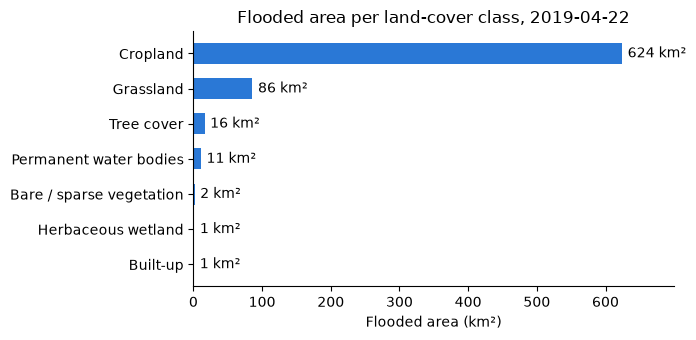

In [3]:
shown = table.loc[table["flooded_km2"] >= 0.5].sort_values(by="flooded_km2")

fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.barh(shown["class"], shown["flooded_km2"], color="#2a78d6", height=0.6)
ax.bar_label(bars, labels=[f"{km2:.0f} km²" for km2 in shown["flooded_km2"]], padding=4)
ax.set_xlabel("Flooded area (km²)")
ax.set_title(f"Flooded area per land-cover class, {cfg.L8_DURING}")
ax.spines[["top", "right"]].set_visible(False)
ax.margins(x=0.12)
fig.tight_layout()
fig.savefig(cfg.FIGURES / "flooded_landcover_bar.png", dpi=200)

## Map

In [4]:
# Flood pixels coloured by their land-cover class.
# The class values (10, 20, ...) are not 0, 1, 2, ..., so remap them to get one palette colour per class.
class_values = list(cfg.WORLDCOVER_COLORS)
class_palette = [cfg.WORLDCOVER_COLORS[value].lstrip("#") for value in class_values]
flooded_landcover = landcover.updateMask(flood).remap(class_values, list(range(len(class_values))))
landcover_colors = {"min": 0, "max": len(class_values) - 1, "palette": class_palette}

m = c.Map(center=(48.5, -97.1), zoom=9)
m.addLayer(landcover, {"bands": ["Map"]}, "ESA WorldCover 2020 (all)", False)
m.addLayer(flooded_landcover, landcover_colors, f"Flooded land cover {cfg.L8_DURING}")
m.add_legend(builtin_legend="ESA_WorldCover")
m

Map(center=[48.5, -97.1], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright',…

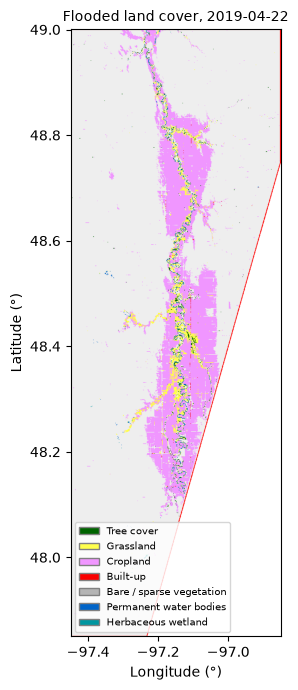

In [5]:
layer = (
    ee.Image(1).clip(aoi).visualize(palette=["eeeeee"])  # light grey = not flooded
    .blend(flooded_landcover.visualize(**landcover_colors))
    .blend(c.outline(aoi))
)
fig, ax = plt.subplots(figsize=(5, 7))
c.plot_map(ax, layer, aoi, f"Flooded land cover, {cfg.L8_DURING}")
names_shown = {name: cfg.WORLDCOVER_COLORS[value] for value, name in cfg.WORLDCOVER_NAMES.items() if name in set(shown["class"])}
ax.legend(handles=c.legend_patches(names_shown), loc="lower left", fontsize=7)
fig.tight_layout()
fig.savefig(cfg.FIGURES / "flooded_landcover_map.png", dpi=200)

## Which classes keep the water? (Sentinel-1)
For each Sentinel-1 date we compute the share of each class that is flooded. A class whose share drops slowly keeps the water longer.
We show the four land classes with the largest area.

In [6]:
vh_before = c.sentinel1_vh_median(cfg.S1_BEFORE_WINDOW, aoi)

rows = []
for day in cfg.S1_TIMELINE:
    vh = c.sentinel1_vh_median(c.one_day(day), aoi)
    flooded = c.area_per_class(c.sar_flood(vh, vh_before), landcover, aoi)
    for value, area_km2 in total_per_class.items():
        rows.append({
            "date": day,
            "class": cfg.WORLDCOVER_NAMES[value],
            "flooded_km2": flooded.get(value, 0.0),
            "class_flooded_%": 100 * flooded.get(value, 0.0) / area_km2,
        })

retention = pd.DataFrame(rows).round(1)
retention.to_csv(cfg.TABLES / "flooded_landcover_timeline.csv", index=False)
retention.pivot(index="class", columns="date", values="class_flooded_%")

date,2019-04-22,2019-05-04,2019-05-16,2019-08-20
class,,,,
Bare / sparse vegetation,8.4,4.9,2.8,1.2
Built-up,7.2,2.1,1.1,0.2
Cropland,15.3,13.5,8.4,0.4
Grassland,12.4,9.0,1.7,1.9
Herbaceous wetland,20.8,11.4,2.6,5.9
Permanent water bodies,17.0,13.9,4.0,0.0
Tree cover,0.8,0.5,0.1,0.1


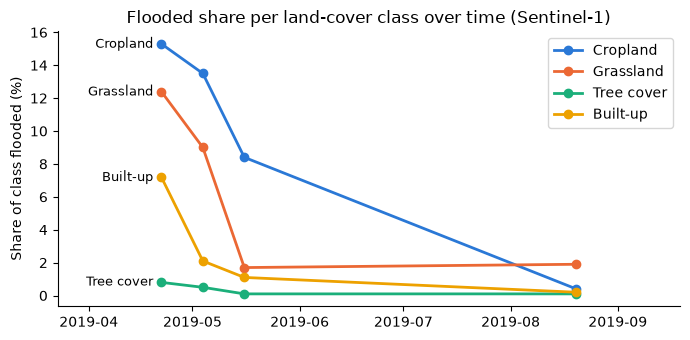

In [7]:
main_classes = ["Cropland", "Grassland", "Tree cover", "Built-up"]
colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

fig, ax = plt.subplots(figsize=(7, 3.5))
for name, color in zip(main_classes, colors):
    rows = retention.loc[retention["class"] == name]
    ax.plot(pd.to_datetime(rows["date"]), rows["class_flooded_%"], marker="o", color=color, linewidth=2, label=name)
    # Name next to the first point (22 Apr)
    first_point = (mdates.datestr2num(rows["date"].iloc[0]), rows["class_flooded_%"].iloc[0])
    ax.annotate(name, first_point, xytext=(-6, 0),
                textcoords="offset points", ha="right", va="center", fontsize=9)
ax.set_ylabel("Share of class flooded (%)")
ax.set_title("Flooded share per land-cover class over time (Sentinel-1)")
ax.spines[["top", "right"]].set_visible(False)
ax.margins(x=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(cfg.FIGURES / "flooded_landcover_timeline.png", dpi=200)

## Notes
- **Flooded land cover on 22 April (optical):** cropland 624 km² (84 % of the flood), grassland 86 km² (12 %), tree cover 16 km² (2 %). Built-up is only 1 km² (3 % of the built-up area): towns along the river are protected by dikes.
- Relative to their size, cropland (18 %), grassland (17 %) and tree cover (13 %) were hit about equally. The study area is mostly flat farmland in the old lake bed of glacial Lake Agassiz.
- **Cropland keeps the water longest (Sentinel-1):** on 16 May, 8.4 % of the cropland was still flooded, i.e. 55 % of its 22 April value. Grassland dropped to 1.7 % (14 % of its 22 April value), built-up to 1.1 %. The fields are very flat and drained by ditches, so water stays in shallow ponds. Grassland lies mostly along the river and drains back into it.
- **Tree cover: the sensors disagree** (optical 13 %, SAR 0.8 %). In April the trees have no leaves, so Landsat sees the water below them. For radar, water under trees makes the signal brighter (trunk–water double bounce), not darker, so our change detection misses it.
- **Built-up:** SAR shows more flooding here (7 %) than optical (3 %). Radar is unreliable between buildings (shadows), so we trust the optical value.
- **Limitations:** WorldCover is from 2020, one year after the flood. Its classes are mapped at 10 m, the flood at 30 m (Landsat) / 10 m (Sentinel-1). The land-cover map itself has errors (overall accuracy ~75 %, Zanaga et al. 2021).